# GT Project — Base Model in One Notebook

**Risk-Constrained Multi-Agent RL for Competitive Food-Delivery Platforms**
*(Stages 1–4 of the project plan: market simulator → RL environment → PPO baseline → two-agent MAPPO, with real-data calibration and a risk/behavior evaluation.)*

**What this notebook does, end to end:**

1. **Calibrates a two-platform food-delivery market from real, free datasets**
   - *Delivery Center: Food & Goods orders in Brazil* (~370k orders with timestamps, delivery cycle times, fees) → demand profile, delivery-delay distribution, market scale, fee structure.
   - *Zomato Bangalore Restaurants* (51k restaurants) → order value (basket) structure and demand concentration, in the Indian market context.
2. **Builds the market simulator + two-agent RL environment** (analytical demand, logit customer choice with multi-homing, courier participation, fulfillment, delays/SLA, platform economics).
3. **Trains the model: two competing MAPPO agents** (Platform A and Platform B learn pricing + courier-incentive strategies via self-play) plus a **PPO single-agent baseline**.
4. **Evaluates everything**: profit, fulfillment, delays, courier-earnings Gini, tail loss with **empirical CVaR₀.₉₅**, collusion proxies (price correlation, parallel increases, benchmark deviation), and the problem statement's training-stability criteria.

**How to run:** Runtime → *Change runtime type* → GPU (T4) is optional; the nets are tiny and CPU is fine. Run all cells top to bottom. Default training sizes take ~10–20 min total; every knob is overridable in the Setup cell.

**Honest claims boundary (per the problem statement):** this is a *simulation-based* study in a calibrated environment — no real-world profitability, no causal claims from proprietary data, no guaranteed collusion prevention. LLM prior / world model / distributional critic (Stages 5–16) build on top of this notebook.

In [ ]:
# ===== Setup =====
import os, sys, math, json, glob, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- runtime knobs (env-var overridable so you can do quick smoke runs) ---
FDM_EPISODES     = int(os.environ.get("FDM_EPISODES", "6000"))    # MAPPO training episodes
FDM_PPO_EPISODES = int(os.environ.get("FDM_PPO_EPISODES", "6000")) # PPO baseline episodes
FDM_EVAL_EPS     = int(os.environ.get("FDM_EVAL_EPS", "12"))      # eval episodes per policy config
FDM_SEED         = int(os.environ.get("FDM_SEED", "0"))

def _ensure(pkg, extra=None):
    try:
        __import__(pkg)
    except ModuleNotFoundError:
        cmd = [sys.executable, "-m", "pip", "install", "-q", pkg] + (extra or [])
        subprocess.run(cmd, check=True)
        __import__(pkg)

_ensure("kagglehub")
_ensure("torch")
import torch
import kagglehub

torch.set_num_threads(2)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| device:", DEVICE)
print("run sizes -> MAPPO episodes:", FDM_EPISODES, "| PPO episodes:", FDM_PPO_EPISODES, "| eval eps:", FDM_EVAL_EPS)

numpy 2.1.3 | pandas 2.2.3 | torch 2.9.0+cpu | device: cpu
run sizes -> MAPPO episodes: 6000 | PPO episodes: 6000 | eval eps: 12


## 1. Real free datasets → calibration

The problem statement requires the simulator to be **calibrated from publicly available aggregate statistics** with explicitly stated assumptions. We use two free Kaggle datasets (anonymous download, no API key needed):

| Dataset | What we take from it |
|---|---|
| [Delivery Center: Food & Goods orders in Brazil](https://www.kaggle.com/datasets/nosbielcs/brazilian-delivery-center) — ~370k orders | hour-of-day / day-of-week **demand profile**, **delivery cycle-time** distribution (→ delay + SLA dynamics), **delivery-fee-to-order-value ratio**, per-hub **market scale** (orders/hour, active drivers) |
| [Zomato Bangalore Restaurants](https://www.kaggle.com/datasets/himanshupoddar/zomato-bangalore-restaurants) — 51k restaurants | **order value (basket)** distribution in ₹, **demand concentration** (votes → Gini), online-ordering share |

Strategy: *temporal & operational dynamics* come from the Brazilian order-level data; *market price structure* (₹ levels) comes from Zomato. Anything neither dataset can identify (e.g. two-platform split, customer price elasticity, rain shocks) stays an explicitly labeled assumption and is swept in the robustness stage of the project.

If a download ever fails (network hiccup), the notebook **does not die** — it falls back to documented default values and marks them "assumed" in the calibration table.

In [ ]:
# ===== Dataset 1: Delivery Center Brazil (order-level food/goods delivery) =====
DC_OK = False
DC_DEFAULTS = dict(base_delay_min=42.0, delay_noise_std=8.0, fee_ratio=0.111,
                   base_lambda=60.0, n_couriers=70, orders_per_courier_hour=1.3)
try:
    dc_dir = kagglehub.dataset_download("nosbielcs/brazilian-delivery-center")
    dcg = lambda name: glob.glob(os.path.join(dc_dir, name))[0]
    stores = pd.read_csv(dcg("stores.csv"), encoding="latin-1")
    orders = pd.read_csv(dcg("orders.csv"), usecols=[
        "order_id", "store_id", "order_status", "order_amount", "order_delivery_fee",
        "order_created_hour", "order_created_day", "order_created_month", "order_created_year",
        "order_moment_created", "order_moment_delivered", "order_metric_cycle_time"])
    deliveries = pd.read_csv(dcg("deliveries.csv"),
                             usecols=["delivery_order_id", "driver_id", "delivery_status"])
    # keep FOOD-segment stores only (this is a food-delivery study)
    food_stores = stores.loc[stores.store_segment == "FOOD", ["store_id", "hub_id"]]
    orders = orders.merge(food_stores, on="store_id", how="inner")
    fin = orders[orders.order_status == "FINISHED"].copy()
    ts = pd.to_datetime(fin.order_moment_created, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    fin["dow"] = ts.dt.dayofweek
    fin = fin.dropna(subset=["dow"])
    fin["dow"] = fin["dow"].astype(int)
    print("Delivery Center: %d FOOD orders finished, %d hubs" % (len(fin), food_stores.hub_id.nunique()))
    DC_OK = True
except Exception as e:
    print("Delivery Center download failed (%s: %s) -> using documented defaults" % (type(e).__name__, e))

100%|██████████| 27.7M/27.7M [00:00<00:00, 127MB/s]

Extracting files...


Delivery Center: 310814 FOOD orders finished, 29 hubs


In [ ]:
# ===== Dataset 2: Zomato Bangalore (market price structure) =====
ZOM_OK = False
ZOM_DEFAULTS = dict(basket=400.0, online_share=0.82, demand_gini=0.60, rating_mean=3.6)
try:
    zom_dir = kagglehub.dataset_download("himanshupoddar/zomato-bangalore-restaurants")
    zom = pd.read_csv(glob.glob(os.path.join(zom_dir, "*.csv"))[0],
                      usecols=["name", "rate", "votes", "approx_cost(for two people)", "online_order"])
    cost = (zom["approx_cost(for two people)"].astype(str).str.replace(",", "", regex=False)
            .pipe(pd.to_numeric, errors="coerce"))
    zom = zom.assign(cost=cost)
    zom = zom.dropna(subset=["cost", "votes"])
    zom = zom[(zom.cost >= 40) & (zom.cost <= 3000)]
    ZOM_OK = True
    print("Zomato: %d restaurants | online-order share %.2f" % (len(zom), (zom.online_order == "Yes").mean()))
except Exception as e:
    print("Zomato download failed (%s: %s) -> using documented defaults" % (type(e).__name__, e))

Using Colab cache for faster access to the 'zomato-bangalore-restaurants' dataset.
Zomato: 51292 restaurants | online-order share 0.59


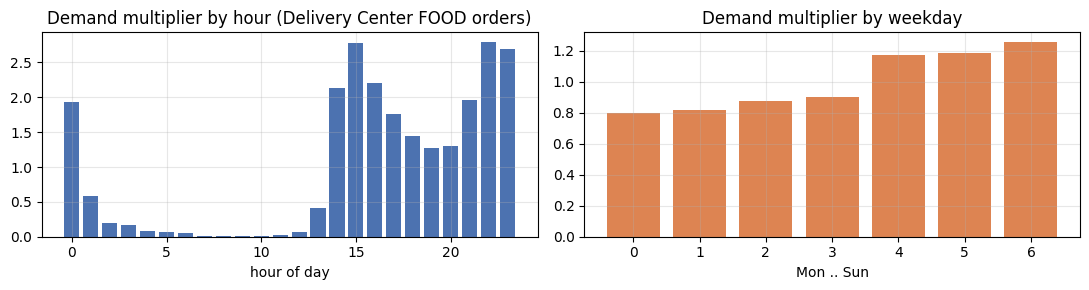

peak hours: [22 15 23] | weakest: [ 7  8 10]
sigma_lambda = 0.12 (assumed)


In [ ]:
# ===== Calibration A: demand profile (hour of day, day of week) =====
hour_profile = None
day_profile = None

if DC_OK:
    # hour-of-day and day-of-week multipliers, normalized to mean 1.0.
    # The raw empirical hour profile spans ~200x (late-night peaks vs morning);
    # we temper it (power 0.6) so a fixed-courier zone can plausibly serve it.
    by_hour = fin.groupby("order_created_hour").size().reindex(range(24), fill_value=0)
    by_dow  = fin.groupby("dow").size().reindex(range(7), fill_value=0)
    hour_profile = (by_hour / by_hour.mean()).to_numpy() ** 0.6
    hour_profile /= hour_profile.mean()
    day_profile  = (by_dow  / by_dow.mean()).to_numpy()
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].bar(range(24), hour_profile, color="#4C72B0")
    ax[0].set_title("Demand multiplier by hour (Delivery Center FOOD orders)")
    ax[0].set_xlabel("hour of day"); ax[0].grid(alpha=.3)
    ax[1].bar(range(7), day_profile, color="#DD8452")
    ax[1].set_title("Demand multiplier by weekday"); ax[1].set_xlabel("Mon .. Sun")
    ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print("peak hours:", np.argsort(hour_profile)[::-1][:3], "| weakest:", np.argsort(hour_profile)[:3])
else:
    # documented fallback: lunch + dinner peaks (industry-standard shape)
    hour_profile = np.array([.45,.30,.22,.18,.18,.22,.35,.60,.85,.90,.85,1.0,
                             1.5,1.7,1.3,1.0,.95,1.05,1.35,1.7,1.85,1.6,1.1,.7])
    hour_profile /= hour_profile.mean()
    day_profile = np.array([.95,.90,.92,.98,1.08,1.15,1.12])
    print("using fallback demand profile (assumed)")

SIGMA_LAMBDA = 0.12   # multiplicative demand noise — assumption (swept in robustness stage)
print("sigma_lambda =", SIGMA_LAMBDA, "(assumed)")

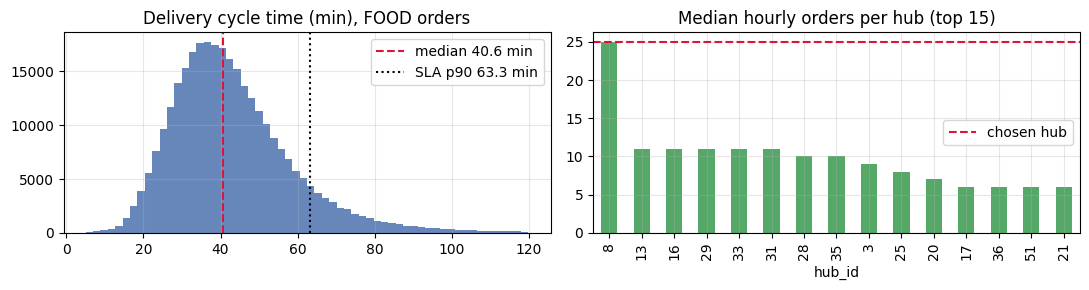

{'base_delay_min': 40.63, 'delay_noise_std': 6.0, 'sla_min': 63.32, 'fee_ratio': 0.11111111111111112, 'base_lambda': 25.0, 'n_couriers': 34}


In [ ]:
# ===== Calibration B: delivery operations + market scale (per-hub zone) =====
calib_ops = {}
if DC_OK:
    # --- delivery cycle time (created -> delivered), robust window 5..120 min
    ct = pd.to_numeric(fin.order_metric_cycle_time, errors="coerce")
    ct = ct[(ct >= 5) & (ct <= 120)]
    calib_ops["base_delay_min"] = float(ct.median())
    # within-hour variation only; the day-level spread is modeled via the load term
    calib_ops["delay_noise_std"] = 6.0
    # severe-delay threshold: problem statement allows "45 min OR > 90th percentile of
    # the calibration distribution" -> with a ~41-min data median we take the p90 route
    calib_ops["sla_min"] = float(max(45.0, ct.quantile(0.90)))

    # --- delivery-fee-to-order-value ratio
    m = fin[(fin.order_delivery_fee > 0) & (fin.order_delivery_fee < fin.order_amount)]
    calib_ops["fee_ratio"] = float((m.order_delivery_fee / m.order_amount).median())

    # --- market scale: demand-anchored staffing of one representative busy hub
    hh = fin.groupby(["hub_id", "order_created_year", "order_created_month",
                      "order_created_day", "order_created_hour"]).size()
    hub_med = hh.groupby("hub_id").median()
    pct75 = hub_med.quantile(.75)
    busy_hubs = hub_med[hub_med >= pct75].index
    chosen = int(hub_med.loc[busy_hubs].idxmax()) if len(busy_hubs) else int(hub_med.idxmax())
    calib_ops["base_lambda"] = float(hub_med.loc[chosen])
    # staff the zone so that at typical participation (0.75) and 1.3 orders/hour/courier
    # the mean load is ~0.75 (scarcity binds only at the calibrated demand peaks)
    calib_ops["n_couriers"] = int(np.clip(round(calib_ops["base_lambda"] / (0.75 * 1.3 * 0.75)), 20, 400))

    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].hist(ct, bins=60, color="#4C72B0", alpha=.85)
    ax[0].axvline(calib_ops["base_delay_min"], color="crimson", ls="--",
                  label="median %.1f min" % calib_ops["base_delay_min"])
    ax[0].axvline(calib_ops["sla_min"], color="black", ls=":",
                  label="SLA p90 %.1f min" % calib_ops["sla_min"])
    ax[0].set_title("Delivery cycle time (min), FOOD orders"); ax[0].legend(); ax[0].grid(alpha=.3)
    hub_med.sort_values(ascending=False).head(15).plot(kind="bar", ax=ax[1], color="#55A868")
    ax[1].axhline(calib_ops["base_lambda"], color="crimson", ls="--", label="chosen hub")
    ax[1].set_title("Median hourly orders per hub (top 15)"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()
else:
    calib_ops = {k: DC_DEFAULTS[k] for k in ("base_delay_min", "delay_noise_std", "fee_ratio",
                                             "base_lambda", "n_couriers")}
    calib_ops["sla_min"] = 45.0
print(calib_ops)

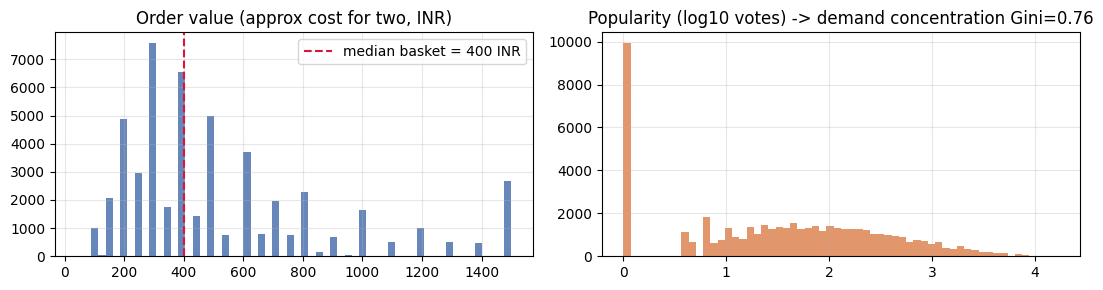

                           parameter              value                               source
   base_lambda (orders/hour in zone)               25.0                      Delivery Center
n_couriers in zone (demand-anchored)                 34                       derived (data)
             orders_per_courier_hour                1.3           assumption (gig-work norm)
       base_delay_min (median cycle)               40.6                      Delivery Center
               delay_noise_std (min)                6.0             assumption (within-hour)
                 SLA threshold (min)               63.3           PS rule: max(45, data p90)
               cancel patience (min)               80.6                derived vs base delay
                  basket (INR/order)              400.0                               Zomato
              delivery_fee_ref (INR)               44.4         derived (fee ratio x basket)
  fixed ops cost/hour (per platform)              220.0 derived (25% o

In [ ]:
# ===== Calibration C: money structure from Zomato + summary table =====
calib_money = {}
if ZOM_OK:
    calib_money["basket"] = float(zom.cost.median())          # order value in INR (meal for two as one order)
    calib_money["online_share"] = float((zom.online_order == "Yes").mean())
    votes_online = zom.loc[zom.online_order == "Yes", "votes"].to_numpy(dtype=float)
    v = np.sort(votes_online); n = v.size
    calib_money["demand_gini"] = float((2 * (np.arange(1, n + 1) * v).sum() - (n + 1) * v.sum()) / (n * v.sum()))
    calib_money["rating_mean"] = float(pd.to_numeric(zom.rate.astype(str).str.split("/").str[0],
                                                     errors="coerce").mean())
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].hist(zom.cost.clip(0, 1500), bins=60, color="#4C72B0", alpha=.85)
    ax[0].axvline(calib_money["basket"], color="crimson", ls="--",
                  label="median basket = %d INR" % calib_money["basket"])
    ax[0].set_title("Order value (approx cost for two, INR)"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].hist(np.log10(zom.votes.clip(lower=1)), bins=60, color="#DD8452", alpha=.85)
    ax[1].set_title("Popularity (log10 votes) -> demand concentration Gini=%.2f" % calib_money["demand_gini"])
    ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()
else:
    calib_money = dict(ZOM_DEFAULTS)

# ---- assemble the calibrated parameters ----
basket = calib_money["basket"]
fee_ref = calib_ops["fee_ratio"] * basket          # fee scales with order value (fee_ratio from data)
# operations overhead ≈ 25% of one platform's commission gross (assumption; a platform
# captures ~40% of zone orders, so its fixed cost must scale with its own volume)
fixed_cost = 0.25 * calib_ops["base_lambda"] * 0.22 * basket * 0.40
patience_mean = max(60.0, calib_ops["base_delay_min"] + 40.0)   # cancel patience vs realized delay
patience_std = max(12.0, 2.0 * calib_ops["delay_noise_std"])

rows = [
    ("base_lambda (orders/hour in zone)", round(calib_ops["base_lambda"], 1), "Delivery Center" if DC_OK else "assumed"),
    ("n_couriers in zone (demand-anchored)", calib_ops["n_couriers"], "derived (data)"),
    ("orders_per_courier_hour", 1.3, "assumption (gig-work norm)"),
    ("base_delay_min (median cycle)", round(calib_ops["base_delay_min"], 1), "Delivery Center" if DC_OK else "assumed"),
    ("delay_noise_std (min)", calib_ops["delay_noise_std"], "assumption (within-hour)"),
    ("SLA threshold (min)", round(calib_ops["sla_min"], 1), "PS rule: max(45, data p90)"),
    ("cancel patience (min)", round(patience_mean, 1), "derived vs base delay"),
    ("basket (INR/order)", basket, "Zomato" if ZOM_OK else "assumed"),
    ("delivery_fee_ref (INR)", round(fee_ref, 1), "derived (fee ratio x basket)"),
    ("fixed ops cost/hour (per platform)", round(fixed_cost, 0), "derived (25% of platform commission)"),
    ("demand concentration Gini", round(calib_money.get("demand_gini", .6), 2), "Zomato" if ZOM_OK else "assumed"),
    ("commission_rate", 0.22, "assumption"),
    ("courier_pay_ref (INR/order)", 35.0, "assumption"),
    ("incentive_ref (INR/order)", 10.0, "assumption"),
    ("share_A / share_B / multi-homing", "0.45 / 0.35 / 0.20", "assumption"),
]
calib_table = pd.DataFrame(rows, columns=["parameter", "value", "source"])
print(calib_table.to_string(index=False))

## 2. Stages 1–2: the market simulator and the RL environment

**The game (from the problem statement).** Two platforms (A, B) choose an action
**aᵢ = (price multiplier, courier incentive)** each hour:
price ∈ {0.8, 0.9, 1.0, 1.1, 1.2} × reference fee, incentive ∈ {0.0, 0.5, 1.0, 1.5, 2.0} × reference incentive — 25 actions each, one simulated week **T = 168 steps**.

**Dynamics (one `step()` = one hour, single forward pass, no fixed points):**

```
demand ~ Poisson(lambda_t)                     # calibrated hour/day profile x weather
customer choice: multinomial logit over (A, B, opt-out)  # multi-homing: both apps compared
couriers: participation responds to incentive + LAGGED earnings (EWMA, alpha=0.3)
          multi-homers pick the more attractive platform that hour
fulfillment: orders <= capacity; overflow customers may switch platform (ablatable)
delay: base x (1 + 0.5*load) x rain + noise  ->  SLA breaches (>45 min), cancellations
economics: profit = commission + delivery fee - courier pay - incentive - fixed cost
```

**Environment (RL view):** 14-dim partial observation per platform (time, demand, own/competitor prices, *noisy* courier capacity, fulfillment/earnings/delay/cancel EWMAs, rain). Reward = (profit − 0.5·routine-delay-minutes)/1000. Tail-loss components (failures F, severe SLA breaches S, extreme incentive overspend W) are tracked per episode for the risk evaluation — never double-counted into the step reward.

In [ ]:
# ===== Stage 1: the analytical market simulator =====
from dataclasses import dataclass, field

PRICE_GRID = (0.8, 0.9, 1.0, 1.1, 1.2)
INCENTIVE_GRID = (0.0, 0.5, 1.0, 1.5, 2.0)
N_ACTIONS = len(PRICE_GRID) * len(INCENTIVE_GRID)
UNFULFILLED_WAIT_MIN, MAX_DELAY_MIN = 90.0, 120.0

def normal_sf(x, mu, sigma):
    return 0.5 * math.erfc((x - mu) / (sigma * math.sqrt(2.0)))

@dataclass
class MarketConfig:
    seed: int = FDM_SEED
    T: int = 168
    base_lambda: float = 60.0
    sigma_lambda: float = 0.12
    hour_profile: tuple = tuple(hour_profile)
    day_profile: tuple = tuple(day_profile)
    rain_start_p: float = 0.15
    rain_stay_p: float = 0.60
    rain_demand_mult: float = 1.20
    rain_delay_mult: float = 1.15
    beta_price: float = -2.2
    beta_incentive: float = 0.45
    beta_wait: float = -1.6
    brand_A: float = 0.15
    brand_B: float = 0.0
    wait_ref: float = 30.0
    n_couriers: int = 60
    share_A: float = 0.45
    share_B: float = 0.35
    base_participation: float = 0.75
    kappa_incentive: float = 0.15
    kappa_earn: float = 0.50
    earn_ref: float = 55.0
    orders_per_courier_hour: float = 1.3
    courier_skill_cv: float = 0.40
    ewma_alpha: float = 0.3
    ewma_wait_alpha: float = 0.4
    base_delay_min: float = 42.0
    delay_load_coef: float = 0.3
    delay_noise_std: float = 6.0
    sla_min: float = 45.0
    patience_mean: float = 60.0
    patience_std: float = 12.0
    switching_share: float = 0.35
    enable_courier_switching: bool = True
    affiliation_switch_p: float = 0.15
    basket: float = 400.0
    commission_rate: float = 0.22
    delivery_fee_ref: float = 44.0
    courier_pay_ref: float = 35.0
    incentive_ref: float = 10.0
    fixed_cost_per_step: float = 1500.0
    c_delay: float = 0.25
    reward_scale: float = 1000.0
    c_f: float = 10.0
    c_s: float = 10.0
    c_w: float = 10.0
    spend_headroom: float = 1.5
    cvar_beta: float = 0.95
    demand_ewma_alpha: float = 0.2
    obs_noise_std: float = 0.10

    @property
    def mean_lambda(self):
        return self.base_lambda

def _logit_shares(cfg, pa, wa, pb, wb, wait_a, wait_b):
    ua = cfg.brand_A + cfg.beta_price * (pa - 1.0) + cfg.beta_incentive * wa + cfg.beta_wait * (wait_a / cfg.wait_ref - 1.0)
    ub = cfg.brand_B + cfg.beta_price * (pb - 1.0) + cfg.beta_incentive * wb + cfg.beta_wait * (wait_b / cfg.wait_ref - 1.0)
    m = max(ua, ub, 0.0)
    ea, eb, e0 = math.exp(ua - m), math.exp(ub - m), math.exp(-m)
    z = ea + eb + e0
    return ea / z, eb / z, e0 / z

def _participation(cfg, w, ewma_earn):
    gap = ewma_earn / cfg.earn_ref - 1.0
    return float(np.clip(cfg.base_participation + cfg.kappa_incentive * (w - 1.0) + cfg.kappa_earn * gap, 0.10, 1.0))

def analytical_core(cfg, demand, rain, pa, wa, pb, wb, wait_a, wait_b, earn_a, earn_b):
    """Deterministic expectation of one market step (no RNG, no side effects)."""
    sa, sb, _ = _logit_shares(cfg, pa, wa, pb, wb, wait_a, wait_b)
    na, nb = demand * sa, demand * sb
    part_a = _participation(cfg, wa, earn_a)
    part_b = _participation(cfg, wb, earn_b)
    n_multi_active = cfg.n_couriers * (1.0 - cfg.share_A - cfg.share_B) * 0.5 * (part_a + part_b)
    if cfg.enable_courier_switching:
        aa = wa + cfg.kappa_earn * (earn_a / cfg.earn_ref - 1.0)
        ab = wb + cfg.kappa_earn * (earn_b / cfg.earn_ref - 1.0)
        m = max(aa, ab)
        wta = math.exp(aa - m) / (math.exp(aa - m) + math.exp(ab - m))
    else:
        wta = 0.5
    active_a = cfg.n_couriers * cfg.share_A * part_a + n_multi_active * wta
    active_b = cfg.n_couriers * cfg.share_B * part_b + n_multi_active * (1.0 - wta)
    cap_a, cap_b = active_a * cfg.orders_per_courier_hour, active_b * cfg.orders_per_courier_hour
    ful_a, un_a = min(na, cap_a), max(na - cap_a, 0.0)
    ful_b, un_b = min(nb, cap_b), max(nb - cap_b, 0.0)
    if cfg.enable_courier_switching:
        moved_ab = min(un_a * cfg.switching_share, max(cap_b - ful_b, 0.0))
        moved_ba = min(un_b * cfg.switching_share, max(cap_a - ful_a, 0.0))
        ful_a += moved_ba; ful_b += moved_ab; un_a -= moved_ab; un_b -= moved_ba
    delay = {}
    for name, n, cap in (("a", na, cap_a), ("b", nb, cap_b)):
        d = cfg.base_delay_min * (1.0 + cfg.delay_load_coef * (n / max(cap, 1e-9)))
        if rain:
            d *= cfg.rain_delay_mult
        d = min(d, MAX_DELAY_MIN)
        sig = math.sqrt(cfg.delay_noise_std ** 2 + cfg.patience_std ** 2)
        delay[name] = dict(delay=d, sla_rate=normal_sf(cfg.sla_min, d, cfg.delay_noise_std),
                           cancel_rate=normal_sf(cfg.patience_mean, d, sig))
    eff_a = max(ful_a * (1.0 - delay["a"]["cancel_rate"]), 0.0)
    eff_b = max(ful_b * (1.0 - delay["b"]["cancel_rate"]), 0.0)
    econ = {}
    for name, p, w, eff in (("a", pa, wa, eff_a), ("b", pb, wb, eff_b)):
        rev = (cfg.commission_rate * cfg.basket + cfg.delivery_fee_ref * p) * eff
        pay = (cfg.courier_pay_ref + cfg.incentive_ref * w) * eff
        econ[name] = dict(revenue=rev, payout=pay, incentive_spend=cfg.incentive_ref * w * eff,
                          profit=rev - pay - cfg.fixed_cost_per_step,
                          routine_delay_cost=cfg.c_delay * eff * min(delay[name]["delay"], cfg.sla_min))
    d_eff_a = (eff_a * delay["a"]["delay"] + un_a * UNFULFILLED_WAIT_MIN) / max(na, 1e-9)
    d_eff_b = (eff_b * delay["b"]["delay"] + un_b * UNFULFILLED_WAIT_MIN) / max(nb, 1e-9)
    out = dict(shares=(sa, sb, 1.0 - sa - sb), n_a=na, n_b=nb, cap_a=cap_a, cap_b=cap_b,
               active_a=active_a, active_b=active_b, ful_a=ful_a, ful_b=ful_b,
               un_a=un_a, un_b=un_b, eff_a=eff_a, eff_b=eff_b,
               delay_a=delay["a"]["delay"], delay_b=delay["b"]["delay"],
               sla_a=delay["a"]["sla_rate"], sla_b=delay["b"]["sla_rate"],
               d_eff_a=d_eff_a, d_eff_b=d_eff_b)
    for name in ("a", "b"):
        for k, v in econ[name].items():
            out[k + "_" + name] = v
    return out

@dataclass
class CourierState:
    primary: np.ndarray
    count_a: np.ndarray
    count_b: np.ndarray
    z: np.ndarray
    earnings: np.ndarray
    served_a: np.ndarray
    served_b: np.ndarray
    skill: np.ndarray

@dataclass
class StepRecord:
    t: int; hour: int; dow: int; rain: bool; lam: float; demand: int
    p_a: float; w_a: float; p_b: float; w_b: float
    n_a: float; n_b: float; cap_a: float; cap_b: float
    fulfilled_a: float; fulfilled_b: float; unfulfilled_a: float; unfulfilled_b: float
    cancel_a: float; cancel_b: float; delay_a: float; delay_b: float
    sla_a: float; sla_b: float; profit_a: float; profit_b: float
    revenue_a: float; revenue_b: float
    incentive_spend_a: float; incentive_spend_b: float
    routine_delay_cost_a: float; routine_delay_cost_b: float

class Simulator:
    def __init__(self, cfg):
        self.cfg = cfg
        self.rng = np.random.default_rng(cfg.seed)
        self.reset()

    def reset(self):
        cfg, n = self.cfg, self.cfg.n_couriers
        self.rng = np.random.default_rng(cfg.seed)
        na = int(round(n * cfg.share_A)); nb = int(round(n * cfg.share_B))
        primary = np.full(n, 2, dtype=np.int8); primary[:na] = 0; primary[na:na + nb] = 1
        sig = cfg.courier_skill_cv
        skill = self.rng.lognormal(-0.5 * sig ** 2, sig, n)
        self.st = dict(t=0, rain=False,
                       ewma_wait_a=cfg.base_delay_min, ewma_wait_b=cfg.base_delay_min,
                       ewma_earn_a=cfg.earn_ref, ewma_earn_b=cfg.earn_ref,
                       ewma_demand=cfg.mean_lambda,
                       ewma_ful_a=1.0, ewma_ful_b=1.0, ewma_can_a=0.0, ewma_can_b=0.0)
        self.cs = CourierState(primary=primary,
                               count_a=(primary == 0).astype(float), count_b=(primary == 1).astype(float),
                               z=np.where(primary == 0, 0, 1).astype(np.int8),
                               earnings=np.zeros(n), served_a=np.zeros(n, bool), served_b=np.zeros(n, bool),
                               skill=skill)
        self.records = []

    def snapshot_noise(self):
        return {"bg": self.rng.bit_generator.state}

    def restore_noise(self, snap):
        self.rng.bit_generator.state = snap["bg"]

    def step(self, a_a, a_b):
        cfg, st = self.cfg, self.st
        pa, wa = PRICE_GRID[int(a_a[0])], INCENTIVE_GRID[int(a_a[1])]
        pb, wb = PRICE_GRID[int(a_b[0])], INCENTIVE_GRID[int(a_b[1])]
        t, hour, dow = st["t"], st["t"] % 24, st["t"] // 24
        if hour == 0:
            st["rain"] = bool(self.rng.random() < cfg.rain_start_p)
        else:
            st["rain"] = bool(self.rng.random() < (cfg.rain_stay_p if st["rain"] else cfg.rain_start_p))
        lam = (cfg.base_lambda * cfg.hour_profile[hour] * cfg.day_profile[dow]
               * (cfg.rain_demand_mult if st["rain"] else 1.0)
               * (1.0 + self.rng.normal(0.0, cfg.sigma_lambda)))
        demand = int(self.rng.poisson(max(lam, 0.0)))
        out = analytical_core(cfg, demand, st["rain"], pa, wa, pb, wb,
                              st["ewma_wait_a"], st["ewma_wait_b"], st["ewma_earn_a"], st["ewma_earn_b"])
        # action-invariant noise stream (CRN-ready): one uniform per customer
        u = self.rng.random(demand) if demand else np.empty(0)
        s_a, s_b = out["shares"][0], out["shares"][1]
        n_a = float((u < s_a).sum())
        n_b = float(((u >= s_a) & (u < s_a + s_b)).sum())
        ful_a, ful_b = min(n_a, out["cap_a"]), min(n_b, out["cap_b"])
        un_a, un_b = n_a - ful_a, n_b - ful_b
        if cfg.enable_courier_switching:
            moved_ab = min(un_a * cfg.switching_share, max(out["cap_b"] - ful_b, 0.0))
            moved_ba = min(un_b * cfg.switching_share, max(out["cap_a"] - ful_a, 0.0))
            ful_a += moved_ba; ful_b += moved_ab; un_a -= moved_ab; un_b -= moved_ba
        sig_c = math.sqrt(cfg.delay_noise_std ** 2 + cfg.patience_std ** 2)
        can_a = ful_a * normal_sf(cfg.patience_mean, out["delay_a"], sig_c)
        can_b = ful_b * normal_sf(cfg.patience_mean, out["delay_b"], sig_c)
        eff_a, eff_b = max(ful_a - can_a, 0.0), max(ful_b - can_b, 0.0)
        rev_a = (cfg.commission_rate * cfg.basket + cfg.delivery_fee_ref * pa) * eff_a
        rev_b = (cfg.commission_rate * cfg.basket + cfg.delivery_fee_ref * pb) * eff_b
        spend_a = cfg.incentive_ref * wa * eff_a
        spend_b = cfg.incentive_ref * wb * eff_b
        rdc_a = cfg.c_delay * eff_a * min(out["delay_a"], cfg.sla_min)
        rdc_b = cfg.c_delay * eff_b * min(out["delay_b"], cfg.sla_min)
        prof_a = rev_a - (cfg.courier_pay_ref * eff_a + spend_a) - cfg.fixed_cost_per_step
        prof_b = rev_b - (cfg.courier_pay_ref * eff_b + spend_b) - cfg.fixed_cost_per_step
        rec = StepRecord(t=t, hour=hour, dow=dow, rain=st["rain"], lam=lam, demand=demand,
                         p_a=pa, w_a=wa, p_b=pb, w_b=wb, n_a=n_a, n_b=n_b,
                         cap_a=out["cap_a"], cap_b=out["cap_b"],
                         fulfilled_a=ful_a, fulfilled_b=ful_b, unfulfilled_a=un_a, unfulfilled_b=un_b,
                         cancel_a=can_a, cancel_b=can_b, delay_a=out["delay_a"], delay_b=out["delay_b"],
                         sla_a=out["sla_a"], sla_b=out["sla_b"], profit_a=prof_a, profit_b=prof_b,
                         revenue_a=rev_a, revenue_b=rev_b,
                         incentive_spend_a=spend_a, incentive_spend_b=spend_b,
                         routine_delay_cost_a=rdc_a, routine_delay_cost_b=rdc_b)
        self.records.append(rec)
        self._assign_couriers(rec, out)
        self._update_state(rec, out)
        st["t"] += 1
        return rec

    def _assign_couriers(self, rec, out):
        cfg, cs, st = self.cfg, self.cs, self.st
        cs.served_a[:] = False; cs.served_b[:] = False
        n = cfg.n_couriers
        u_part, u_choice, u_rank = self.rng.random(n), self.rng.random(n), self.rng.random(n)
        part_a = _participation(cfg, rec.w_a, st["ewma_earn_a"])
        part_b = _participation(cfg, rec.w_b, st["ewma_earn_b"])
        if cfg.enable_courier_switching:
            aa = rec.w_a + cfg.kappa_earn * (st["ewma_earn_a"] / cfg.earn_ref - 1.0)
            ab = rec.w_b + cfg.kappa_earn * (st["ewma_earn_b"] / cfg.earn_ref - 1.0)
            m = max(aa, ab)
            wta = math.exp(aa - m) / (math.exp(aa - m) + math.exp(ab - m))
        else:
            wta = 0.5
        is_a, is_b, is_m = cs.primary == 0, cs.primary == 1, cs.primary == 2
        part_vec = np.where(is_a, part_a, np.where(is_b, part_b, 0.5 * (part_a + part_b)))
        active = u_part < part_vec
        m_to_a = active & is_m & (u_choice < wta)
        act_a = (is_a & active) | m_to_a
        act_b = (is_b & active) | (active & is_m & ~m_to_a)
        eff_a = max(rec.fulfilled_a - rec.cancel_a, 0.0)
        eff_b = max(rec.fulfilled_b - rec.cancel_b, 0.0)
        self._distribute(act_a, u_rank, eff_a, cfg.courier_pay_ref + cfg.incentive_ref * rec.w_a, cs.served_a)
        self._distribute(act_b, u_rank, eff_b, cfg.courier_pay_ref + cfg.incentive_ref * rec.w_b, cs.served_b)
        st["real_earn_a"] = ((rec.incentive_spend_a + cfg.courier_pay_ref * eff_a) / max(act_a.sum(), 1)) if act_a.sum() else cfg.earn_ref
        st["real_earn_b"] = ((rec.incentive_spend_b + cfg.courier_pay_ref * eff_b) / max(act_b.sum(), 1)) if act_b.sum() else cfg.earn_ref

    def _distribute(self, active, u_rank, eff_orders, per_order_pay, flag):
        cfg, cs = self.cfg, self.cs
        idx = np.flatnonzero(active)
        if idx.size == 0 or eff_orders < 1.0:
            return
        flag[idx] = True
        skill = np.maximum(cs.skill[idx], 1e-6)
        raw = eff_orders * skill / skill.sum()
        counts = np.floor(raw)
        resid = int(round(eff_orders - counts.sum()))
        if resid:
            tie = (raw - counts) + 1e-6 * u_rank[idx]
            counts[np.argsort(tie)[::-1][:resid]] += 1.0
        cs.earnings[idx] += counts * per_order_pay

    def _update_state(self, rec, out):
        cfg, st, cs = self.cfg, self.st, self.cs
        a = cfg.ewma_alpha
        st["ewma_earn_a"] = (1 - a) * st["ewma_earn_a"] + a * st["real_earn_a"]
        st["ewma_earn_b"] = (1 - a) * st["ewma_earn_b"] + a * st["real_earn_b"]
        aw = cfg.ewma_wait_alpha
        st["ewma_wait_a"] = (1 - aw) * st["ewma_wait_a"] + aw * out["d_eff_a"]
        st["ewma_wait_b"] = (1 - aw) * st["ewma_wait_b"] + aw * out["d_eff_b"]
        ad = cfg.demand_ewma_alpha
        st["ewma_demand"] = (1 - ad) * st["ewma_demand"] + ad * rec.demand
        or_a = rec.fulfilled_a + rec.unfulfilled_a
        or_b = rec.fulfilled_b + rec.unfulfilled_b
        st["ewma_ful_a"] = (1 - ad) * st["ewma_ful_a"] + ad * rec.fulfilled_a / max(or_a, 1e-9)
        st["ewma_ful_b"] = (1 - ad) * st["ewma_ful_b"] + ad * rec.fulfilled_b / max(or_b, 1e-9)
        st["ewma_can_a"] = (1 - ad) * st["ewma_can_a"] + ad * rec.cancel_a / max(rec.fulfilled_a, 1e-9)
        st["ewma_can_b"] = (1 - ad) * st["ewma_can_b"] + ad * rec.cancel_b / max(rec.fulfilled_b, 1e-9)
        decay = 1.0 - 1.0 / 24.0
        cs.count_a *= decay; cs.count_b *= decay
        cs.count_a += cs.served_a; cs.count_b += cs.served_b
        prev_z = cs.z.copy()
        cs.z = np.where(cs.count_a > cs.count_b, 0, np.where(cs.count_b > cs.count_a, 1, prev_z)).astype(np.int8)
        if cfg.enable_courier_switching and rec.t % 24 == 23:
            gap_a = max(0.0, (st["ewma_earn_b"] - st["ewma_earn_a"]) / cfg.earn_ref)
            gap_b = max(0.0, (st["ewma_earn_a"] - st["ewma_earn_b"]) / cfg.earn_ref)
            sw_ab = (cs.primary == 0) & (self.rng.random(cs.primary.size) < min(cfg.affiliation_switch_p * gap_a, 0.5))
            sw_ba = (cs.primary == 1) & (self.rng.random(cs.primary.size) < min(cfg.affiliation_switch_p * gap_b, 0.5))
            cs.primary = np.where(sw_ab, 1, np.where(sw_ba, 0, cs.primary))

print("Simulator classes defined.")

Simulator classes defined.


In [ ]:
# ===== Stage 2: two-agent RL environment + baseline policies =====
OBS_DIM = 14

def action_to_pair(a):
    return divmod(int(a), len(INCENTIVE_GRID))

def pair_to_action(pair):
    return int(pair[0]) * len(INCENTIVE_GRID) + int(pair[1])

class FoodDeliveryEnv:
    def __init__(self, cfg):
        self.cfg = cfg
        self.sim = Simulator(cfg)
        self._last = {"A": (1.0, 1.0), "B": (1.0, 1.0)}

    def reset(self, seed=None):
        if seed is not None:
            self.cfg.seed = seed
        self.sim.reset()
        self._last = {"A": (1.0, 1.0), "B": (1.0, 1.0)}
        oa, ob = self._obs(noisy=True)
        return {"A": oa, "B": ob}

    def step(self, actions):
        pairs = {k: action_to_pair(v) for k, v in actions.items()}
        self._last = {"A": (PRICE_GRID[pairs["A"][0]], INCENTIVE_GRID[pairs["A"][1]]),
                      "B": (PRICE_GRID[pairs["B"][0]], INCENTIVE_GRID[pairs["B"][1]])}
        rec = self.sim.step(pairs["A"], pairs["B"])
        oa, ob = self._obs(noisy=True)
        rewards = {"A": (rec.profit_a - rec.routine_delay_cost_a) / self.cfg.reward_scale,
                   "B": (rec.profit_b - rec.routine_delay_cost_b) / self.cfg.reward_scale}
        info = {"record": rec, "actions_pair": pairs}
        return {"A": oa, "B": ob}, rewards, False, (self.sim.st["t"] >= self.cfg.T), info

    def _obs(self, noisy):
        cfg, st, sim = self.cfg, self.sim.st, self.sim
        rec = sim.records[-1] if sim.records else None
        hour, t = st["t"] % 24, st["t"]
        cap_ref = cfg.n_couriers * cfg.orders_per_courier_hour * cfg.base_participation
        def one(side):
            own_p, own_w = self._last[side]
            comp_p, comp_w = self._last["B" if side == "A" else "A"]
            if rec is None:
                cap = cap_ref
            else:
                cap = (rec.cap_a if side == "A" else rec.cap_b)
                if noisy:
                    cap *= 1.0 + sim.rng.normal(0.0, cfg.obs_noise_std)
            return np.array([
                np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
                (t // 24) / 6.0, 1.0 if st["rain"] else 0.0,
                st["ewma_demand"] / cfg.mean_lambda,
                (own_p - 1.0) / 0.2, (own_w - 1.0) / 1.0,
                (comp_p - 1.0) / 0.2, (comp_w - 1.0) / 1.0,
                cap / cap_ref,
                st["ewma_ful_a"] if side == "A" else st["ewma_ful_b"],
                (st["ewma_earn_a"] if side == "A" else st["ewma_earn_b"]) / cfg.earn_ref - 1.0,
                (st["ewma_wait_a"] if side == "A" else st["ewma_wait_b"]) / cfg.sla_min,
                st["ewma_can_a"] if side == "A" else st["ewma_can_b"]], dtype=np.float64)
        return one("A"), one("B")

# ---------- baseline policies (only public information) ----------
class FixedPolicy:
    def __init__(self, price=1.0, incentive=1.0):
        self.pair = [min(range(len(PRICE_GRID)), key=lambda i: abs(PRICE_GRID[i] - price)),
                     min(range(len(INCENTIVE_GRID)), key=lambda i: abs(INCENTIVE_GRID[i] - incentive))]
    def act(self, obs, hint=None):
        return pair_to_action(self.pair)

class RandomPolicy:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)
    def act(self, obs, hint=None):
        return int(self.rng.integers(N_ACTIONS))

class RuleBasedPolicy:
    def __init__(self, price=1.0, incentive=1.0):
        self.pair = [min(range(len(PRICE_GRID)), key=lambda i: abs(PRICE_GRID[i] - price)),
                     min(range(len(INCENTIVE_GRID)), key=lambda i: abs(INCENTIVE_GRID[i] - incentive))]
    def act(self, obs, hint=None):
        cap_ratio, demand, comp_norm = obs[9], obs[4], obs[7]
        comp_idx = int(round(comp_norm * 2)) + 2
        if cap_ratio < 0.90:                      # scarce couriers: price up, incentive up
            self.pair[0] = min(self.pair[0] + 1, 4); self.pair[1] = min(self.pair[1] + 1, 4)
        elif cap_ratio > 1.15 and comp_idx < self.pair[0]:
            self.pair[0] = max(comp_idx, 0)       # match cheaper competitor
            self.pair[1] = max(self.pair[1] - 1, 0)
        elif cap_ratio > 1.15 and demand < 0.85:  # slack + weak demand: discount
            self.pair[0] = max(self.pair[0] - 1, 0); self.pair[1] = max(self.pair[1] - 1, 0)
        return pair_to_action(self.pair)

def run_episode(env, pol_a, pol_b, seed=0):
    obs = env.reset(seed=seed)
    done, tot = False, {"A": 0.0, "B": 0.0}
    while not done:
        obs, r, term, trunc, info = env.step({"A": pol_a.act(obs["A"]), "B": pol_b.act(obs["B"])})
        tot["A"] += r["A"]; tot["B"] += r["B"]
        done = term or trunc
    return tot, info

# ---------- build the calibrated market ----------
CFG = MarketConfig(
    base_lambda=calib_ops["base_lambda"], n_couriers=calib_ops["n_couriers"],
    base_delay_min=calib_ops["base_delay_min"], delay_noise_std=calib_ops["delay_noise_std"],
    sla_min=calib_ops["sla_min"], patience_mean=patience_mean, patience_std=patience_std,
    fixed_cost_per_step=fixed_cost, basket=basket, delivery_fee_ref=fee_ref,
    hour_profile=tuple(hour_profile), day_profile=tuple(day_profile), sigma_lambda=SIGMA_LAMBDA)
print("calibrated market: %.0f orders/hour, %d couriers, delay %.1f+-%.1f min (SLA %.0f), basket %.0f INR, fee %.1f INR"
      % (CFG.base_lambda, CFG.n_couriers, CFG.base_delay_min, CFG.delay_noise_std,
         CFG.sla_min, CFG.basket, CFG.delivery_fee_ref))
env = FoodDeliveryEnv(CFG)
tot, info = run_episode(env, FixedPolicy(1.0, 1.0), FixedPolicy(1.0, 1.0), seed=1)
print("neutral week returns: A=%.0f B=%.0f (reward units)" % (tot["A"], tot["B"]))

calibrated market: 25 orders/hour, 34 couriers, delay 40.6+-6.0 min (SLA 63), basket 400 INR, fee 44.4 INR
neutral week returns: A=30 B=20 (reward units)


In [ ]:
# ===== Metrics: problem-statement operational definitions =====
def gini(values):
    e = np.sort(np.asarray(values, dtype=float)); n = e.size; tot = e.sum()
    if n == 0 or tot <= 0:
        return 0.0
    ranks = np.arange(1, n + 1)
    return float((2.0 * (ranks * e).sum() - (n + 1) * tot) / (n * tot))

def cvar(samples, beta=0.95):
    """Empirical CVaR_beta of tail LOSSES (upper tail = worst outcomes)."""
    x = np.sort(np.asarray(samples, dtype=float))[::-1]
    k = max(int(math.ceil((1.0 - beta) * x.size - 1e-9)), 1)
    return float(x[:k].mean())

def volatility(p_series, w_series):
    dp, dw = np.abs(np.diff(p_series)), np.abs(np.diff(w_series))
    return float(0.5 * dp.mean() + 0.5 * (dw / 2.0).mean()) if dp.size else 0.0

def episode_summary(sim, cfg, spend_benchmark=None):
    """Episode-level aggregates incl. tail loss L = c_f*F + c_s*S + c_w*W."""
    recs = sim.records
    cs = sim.cs
    out = {}
    for side, tag in (("a", "A"), ("b", "B")):
        g = lambda f: np.array([getattr(r, f + "_a") if side == "a" else getattr(r, f + "_b") for r in recs])
        orders = g("fulfilled") + g("unfulfilled")
        fulfilled, cancels, sla = g("fulfilled"), g("cancel"), g("sla")
        profit, spend = g("profit"), g("incentive_spend")
        prices, incs, delays = g("p"), g("w"), g("delay")
        F = float((orders - fulfilled + cancels).sum() / max(orders.sum(), 1e-9))
        S = float((sla * fulfilled).sum() / max(fulfilled.sum(), 1e-9))
        W = (max(0.0, spend.mean() / max(spend_benchmark, 1e-9) - cfg.spend_headroom)
             if spend_benchmark else 0.0)
        elig = (cs.z == 0) if side == "a" else (cs.z == 1)
        out[tag] = dict(
            profit_per_hour=float(profit.mean()),
            fulfillment_rate=float(fulfilled.sum() / max(orders.sum(), 1e-9)),
            F=F, S=S, W=W, tail_loss=cfg.c_f * F + cfg.c_s * S + cfg.c_w * W,
            mean_delay_min=float(delays.mean()),
            cancel_rate=float(cancels.sum() / max(fulfilled.sum(), 1e-9)),
            incentive_spend_total=float(spend.sum()),
            price_volatility=volatility(prices, incs),
            mean_price=float(prices.mean()), mean_incentive=float(incs.mean()),
            courier_gini=gini(cs.earnings[elig]) if elig.any() else 0.0)
    return out

def collusion_proxies(recs, nash=None):
    pa = np.array([r.p_a for r in recs]); pb = np.array([r.p_b for r in recs])
    rho = float(np.corrcoef(pa, pb)[0, 1]) if len(pa) > 2 and pa.std() > 1e-12 and pb.std() > 1e-12 else 0.0
    dpa, dpb = np.diff(pa), np.diff(pb)
    pi = float(((dpa > 0) & (dpb > 0)).mean()) if len(dpa) else 0.0
    dev = {}
    if nash is not None:
        dev = {"benchmark_deviation_A": float(np.mean([r.profit_a for r in recs]) - nash["A"]),
               "benchmark_deviation_B": float(np.mean([r.profit_b for r in recs]) - nash["B"])}
    return dict(price_correlation=rho, parallel_increase_freq=pi, **dev)

def compute_nash(cfg, iters=6):
    """Static Bertrand-Nash via best-response iteration on the 25x25 grid."""
    D = cfg.mean_lambda

    def profit_of(side, pa, pb):
        o = analytical_core(cfg, D, False, PRICE_GRID[pa[0]], INCENTIVE_GRID[pa[1]],
                            PRICE_GRID[pb[0]], INCENTIVE_GRID[pb[1]],
                            cfg.base_delay_min, cfg.base_delay_min, cfg.earn_ref, cfg.earn_ref)
        return o["profit_" + side]

    br = lambda fixed, side: max(((pi, wi) for pi in range(5) for wi in range(5)),
                                 key=lambda act: profit_of(side, act, fixed) if side == "a" else profit_of(side, fixed, act))
    pa = pb = (2, 2)
    for _ in range(iters):
        na = br(pb, "a"); nb = br(na, "b")
        if na == pa and nb == pb:
            break
        pa, pb = na, nb
    o = analytical_core(cfg, D, False, PRICE_GRID[pa[0]], INCENTIVE_GRID[pa[1]],
                        PRICE_GRID[pb[0]], INCENTIVE_GRID[pb[1]],
                        cfg.base_delay_min, cfg.base_delay_min, cfg.earn_ref, cfg.earn_ref)
    return {"A": o["profit_a"], "B": o["profit_b"], "action_a": pa, "action_b": pb}

nash = compute_nash(CFG)
SPEND_BENCHMARK = analytical_core(CFG, CFG.mean_lambda, False, PRICE_GRID[nash["action_a"][0]], 1.0,
                                  PRICE_GRID[nash["action_b"][0]], 1.0, CFG.base_delay_min,
                                  CFG.base_delay_min, CFG.earn_ref, CFG.earn_ref)["incentive_spend_a"]
print("Nash benchmark: actions A=%s B=%s, profit/hour A=%.0f B=%.0f, neutral spend/hour=%.0f"
      % (nash["action_a"], nash["action_b"], nash["A"], nash["B"], SPEND_BENCHMARK))
sim = env.sim
s = episode_summary(sim, CFG, spend_benchmark=SPEND_BENCHMARK)
print("neutral week A: fulfill=%.3f F=%.3f S=%.3f gini=%.2f tail=%.2f | B: fulfill=%.3f tail=%.2f"
      % (s["A"]["fulfillment_rate"], s["A"]["F"], s["A"]["S"], s["A"]["courier_gini"],
         s["A"]["tail_loss"], s["B"]["fulfillment_rate"], s["B"]["tail_loss"]))

Nash benchmark: actions A=(0, 4) B=(0, 4), profit/hour A=535 B=429, neutral spend/hour=100
neutral week A: fulfill=0.790 F=0.267 S=0.275 gini=0.22 tail=5.42 | B: fulfill=0.801 tail=5.39


## 3. Stages 3–4: the model — PPO baseline and two-agent MAPPO

**Architecture.** Each platform runs its own **actor** (2×128 MLP → 25-action softmax) and **critic**. MAPPO follows *centralized training, decentralized execution*:

- **Actors** see only the platform's own 14-dim partial observation.
- **Critics** see the *global* view (both observations concatenated, 28 dims) — the centralized value baseline that stabilizes self-play.
- PPO clipped-surrogate objective + GAE(λ) + entropy bonus; the same machinery with one learner gives the Stage-3 PPO baseline (vs a fixed competitor).

**Training loop.** Collect 25 episodes (25×168 steps) per iteration → GAE advantages → 4 epochs of minibatch PPO updates → repeat. The problem statement's training-stability criteria (no divergence, plateau, non-degenerate entropy) are checked automatically after training — a run that fails the gate counts as not done.

In [ ]:
# ===== Stage 3-4: actor-critic networks + PPO/MAPPO trainer =====
import torch
import torch.nn as nn

class Actor(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(),
                                 nn.Linear(hidden, n_actions))
    def dist(self, obs):
        return torch.distributions.Categorical(logits=self.net(obs))

class Critic(nn.Module):
    def __init__(self, in_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def discount_gae(rew, val, done, gamma=0.97, lam=0.95):
    T = len(rew); adv = np.zeros(T, dtype=np.float64); last = 0.0
    for t in reversed(range(T)):
        nv = 0.0 if done[t] else (val[t + 1] if t + 1 < T else 0.0)
        delta = rew[t] + gamma * nv - val[t]
        last = delta + gamma * lam * (1.0 - done[t]) * last
        adv[t] = last
    return adv, adv + val[:T]

def stability_gate(logs, tag, min_entropy=0.2):
    """Problem-statement criteria: (1) no divergence, (2) plateau over the
    TRAILING 20% of training (<10% relative change across consecutive windows),
    (3) non-degenerate entropy over the trailing window."""
    ret = np.array([l["return_" + tag] for l in logs], dtype=float)
    if ret.size < 10:
        return {"tag": tag, "verdict": "SKIP"}
    k = max(int(math.ceil(0.2 * ret.size)), 6)
    tail = ret[-k:]
    spread = (tail.max() - tail.min()) / max(abs(tail.mean()), 1e-9)
    n = max(tail.size // 3, 2)
    means = [tail[-(i + 1) * n: tail.size if i == 0 else tail.size - i * n].mean()
             for i in range(3)][::-1]
    rel = max(abs(means[i + 1] - means[i]) / max(abs(means[0]), 1e-9) for i in range(2))
    ent = np.mean([l.get("entropy_" + tag, 1.0) for l in logs[-k:]])
    checks = {"no_divergence": bool(np.isfinite(ret).all() and spread < 10.0),
              "plateau(<10%/window)": rel < 0.10,
              "entropy>=%.1f" % min_entropy: bool(ent >= min_entropy)}
    failed = [k2 for k2, ok in checks.items() if not ok]
    return {"tag": tag, "verdict": "FAIL" if failed else "PASS", "failed": failed,
            "tail_return": float(tail.mean()), "spread": spread, "rel_change": rel, "entropy": float(ent)}

def train(env_cfg, mode="mappo", episodes=1200, rollout=25, seed=0, device="cpu",
          lr=2.5e-4, gamma=0.97, lam=0.95, clip=0.2, epochs=4, ent_coef=0.015, log_every=50):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = FoodDeliveryEnv(MarketConfig(**{**env_cfg.__dict__, "seed": seed}))
    learners = ["A", "B"] if mode == "mappo" else ["A"]
    obs_dim = OBS_DIM
    crit_in = 2 * OBS_DIM if mode == "mappo" else OBS_DIM
    actors = {a: Actor(obs_dim, N_ACTIONS).to(device) for a in learners}
    critics = {a: Critic(crit_in).to(device) for a in learners}
    opts = {a: torch.optim.Adam(list(actors[a].parameters()) + list(critics[a].parameters()), lr=lr)
            for a in learners}
    fixed_b = FixedPolicy(1.0, 1.0)
    logs, curves = [], []
    ep_global = 0
    t0 = time.time()
    while ep_global < episodes:
        # linear learning-rate decay -> smooth late-training plateau
        frac = max(1.0 - ep_global / episodes, 0.05)
        for a in learners:
            for gparam in opts[a].param_groups:
                gparam["lr"] = lr * frac
        buf = {a: dict(obs=[], obs_actor=[], act=[], logp=[], rew=[], done=[], val=[]) for a in learners}
        ep_ret = {a: [] for a in learners}
        ent_acc = {a: 0.0 for a in learners}; n_steps = 0
        prob_acc = {a: np.zeros(len(PRICE_GRID)) for a in learners}
        for _ in range(rollout):
            ep_global += 1
            obs = env.reset(seed=seed * 100003 + ep_global)
            done = False
            cur = {a: [] for a in learners}
            while not done:
                state_vec = np.concatenate([obs["A"], obs["B"]])
                acts = {}
                with torch.no_grad():
                    for a in learners:
                        # DECENTRALIZED execution: the actor sees only its own obs;
                        # the CRITIC sees the global view (state_vec) in MAPPO mode
                        inp_actor = torch.as_tensor(obs[a], dtype=torch.float32, device=device).unsqueeze(0)
                        inp_critic = torch.as_tensor(state_vec if mode == "mappo" else obs[a],
                                                     dtype=torch.float32, device=device).unsqueeze(0)
                        dist = actors[a].dist(inp_actor)
                        at = dist.sample()
                        buf[a]["obs"].append(state_vec if mode == "mappo" else obs[a])
                        buf[a]["obs_actor"].append(obs[a])
                        buf[a]["act"].append(int(at.item()))
                        buf[a]["logp"].append(float(dist.log_prob(at).item()))
                        buf[a]["val"].append(float(critics[a](inp_critic).item()))
                        ent_acc[a] += float(dist.entropy().item())
                        probs = dist.probs.squeeze(0).cpu().numpy().reshape(len(PRICE_GRID), len(INCENTIVE_GRID)).sum(1)
                        prob_acc[a] += probs
                        acts[a] = int(at.item())
                if "B" not in learners:
                    acts["B"] = fixed_b.act(obs["B"])
                obs, r, term, trunc, info = env.step(acts)
                done = term or trunc
                n_steps += 1
                for a in learners:
                    buf[a]["rew"].append(r[a]); buf[a]["done"].append(float(done))
                    cur[a].append(r[a])
            for a in learners:
                ep_ret[a].append(sum(cur[a]))
        # ---- PPO update per learner
        batch = {a: {} for a in learners}
        for a in learners:
            adv_all, ret_all, obsA_all, obsC_all, act_all, logp_all = [], [], [], [], [], []
            # split the buffer back into episodes at done==1 boundaries
            idxs = [i for i, d in enumerate(buf[a]["done"]) if d > 0.5]
            start = 0
            for end in idxs:
                sl = slice(start, end + 1)
                rew = np.array(buf[a]["rew"][sl]); val = np.array(buf[a]["val"][sl] + [0.0])
                dn = np.array(buf[a]["done"][sl])
                adv, ret = discount_gae(rew, val, dn, gamma, lam)
                adv_all.append(adv); ret_all.append(ret)
                obsA_all += buf[a]["obs_actor"][sl]
                obsC_all += buf[a]["obs"][sl]
                act_all += buf[a]["act"][sl]; logp_all += buf[a]["logp"][sl]
                start = end + 1
            adv_all = np.concatenate(adv_all); ret_all = np.concatenate(ret_all)
            batch[a] = dict(obs_actor=np.array(obsA_all, dtype=np.float32),
                            obs_critic=np.array(obsC_all, dtype=np.float32),
                            act=np.array(act_all, dtype=np.int64),
                            logp=np.array(logp_all, dtype=np.float32),
                            adv=(adv_all - adv_all.mean()) / (adv_all.std() + 1e-8),
                            ret=ret_all.astype(np.float32))
        for a in learners:
            b = batch[a]; N = len(b["act"])
            obsA_t = torch.as_tensor(b["obs_actor"], device=device)
            obsC_t = torch.as_tensor(b["obs_critic"], device=device)
            act_t = torch.as_tensor(b["act"], device=device)
            logp_t = torch.as_tensor(b["logp"], device=device)
            adv_t = torch.as_tensor(b["adv"], dtype=torch.float32, device=device)
            ret_t = torch.as_tensor(b["ret"], device=device)
            for _ in range(epochs):
                perm = torch.randperm(N, device=device)
                for mb in torch.split(perm, 1024):
                    dist = actors[a].dist(obsA_t[mb])
                    new_logp = dist.log_prob(act_t[mb])
                    ratio = torch.exp(new_logp - logp_t[mb])
                    pi_loss = -torch.min(ratio * adv_t[mb],
                                         torch.clamp(ratio, 1 - clip, 1 + clip) * adv_t[mb]).mean()
                    v_loss = 0.5 * ((critics[a](obsC_t[mb]) - ret_t[mb]) ** 2).mean()
                    loss = pi_loss + v_loss - ent_coef * dist.entropy().mean()
                    opts[a].zero_grad(); loss.backward()
                    nn.utils.clip_grad_norm_(list(actors[a].parameters()) + list(critics[a].parameters()), 0.5)
                    opts[a].step()
        # ---- logging
        if ep_global % log_every == 0 or ep_global >= episodes:
            rec = {"episode": ep_global}
            for a in learners:
                rec["return_" + a] = float(np.mean(ep_ret[a]))
                rec["entropy_" + a] = ent_acc[a] / max(n_steps, 1)
                pm = prob_acc[a] / max(prob_acc[a].sum(), 1e-9)
                rec["p_mass_" + a] = {str(PRICE_GRID[i]): float(pm[i]) for i in range(len(PRICE_GRID))}
            logs.append(rec)
            curves.append((ep_global, *[rec["return_" + a] for a in learners]))
            print("ep %5d | %s | %s" % (ep_global,
                  " ".join("ret_%s=%8.1f" % (a, rec["return_" + a]) for a in learners),
                  " ".join("H_%s=%.2f" % (a, rec["entropy_" + a]) for a in learners)),
                  "| %.0fs" % (time.time() - t0))
    return dict(actors=actors, critics=critics, logs=logs, curves=curves, learners=learners)

def plot_curves(curves, learners, title):
    arr = np.array(curves, dtype=float)
    plt.figure(figsize=(8, 3.2))
    for i, a in enumerate(learners):
        col = arr[:, i + 1]
        plt.plot(arr[:, 0], col, alpha=.25, color="C%d" % i)
        w = max(len(col) // 10, 1)
        smooth = np.convolve(col, np.ones(w) / w, mode="valid")
        plt.plot(arr[w - 1:, 0], smooth, color="C%d" % i, label="platform %s (smoothed)" % a)
    plt.xlabel("episode"); plt.ylabel("episode return"); plt.title(title)
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

ep    50 | ret_A=    28.5 ret_B=    15.7 | H_A=3.21 H_B=3.21 | 9s
ep   100 | ret_A=    29.8 ret_B=    17.5 | H_A=3.20 H_B=3.20 | 19s
ep   150 | ret_A=    31.4 ret_B=    18.6 | H_A=3.16 H_B=3.16 | 28s
ep   200 | ret_A=    33.9 ret_B=    19.9 | H_A=3.05 H_B=3.09 | 37s
ep   250 | ret_A=    35.4 ret_B=    21.0 | H_A=2.92 H_B=2.96 | 47s
ep   300 | ret_A=    36.3 ret_B=    23.4 | H_A=2.73 H_B=2.84 | 56s
ep   350 | ret_A=    38.7 ret_B=    24.2 | H_A=2.57 H_B=2.71 | 66s
ep   400 | ret_A=    38.8 ret_B=    25.3 | H_A=2.41 H_B=2.63 | 75s
ep   450 | ret_A=    39.5 ret_B=    25.6 | H_A=2.24 H_B=2.48 | 85s
ep   500 | ret_A=    39.7 ret_B=    26.5 | H_A=2.15 H_B=2.45 | 94s
ep   550 | ret_A=    39.7 ret_B=    25.5 | H_A=2.17 H_B=2.40 | 104s
ep   600 | ret_A=    40.9 ret_B=    27.2 | H_A=1.95 H_B=2.37 | 113s
ep   650 | ret_A=    40.4 ret_B=    26.5 | H_A=1.95 H_B=2.20 | 123s
ep   700 | ret_A=    41.3 ret_B=    27.4 | H_A=2.07 H_B=2.14 | 132s
ep   750 | ret_A=    41.8 ret_B=    27.9 | H_A=2.02 H_B=2.0

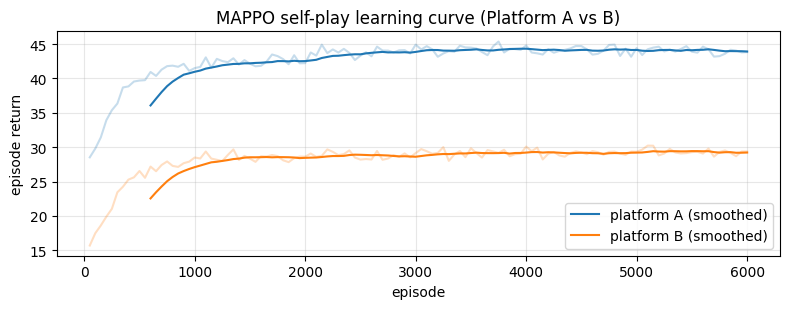

{'tag': 'A', 'verdict': 'PASS', 'failed': [], 'tail_return': 43.96428568772774, 'spread': np.float64(0.03495209990873639), 'rel_change': np.float64(0.00898658579822023), 'entropy': 1.5869124045463219}
{'tag': 'B', 'verdict': 'PASS', 'failed': [], 'tail_return': 29.305700670837084, 'spread': np.float64(0.05456739404054086), 'rel_change': np.float64(0.006630853693031629), 'entropy': 1.7011016423503555}
MAPPO training-stability gate: PASS


In [ ]:
# ===== Stage 4: train the two-agent MAPPO model (self-play) =====
mappo = train(CFG, mode="mappo", episodes=FDM_EPISODES, seed=FDM_SEED, device=DEVICE)
plot_curves(mappo["curves"], mappo["learners"], "MAPPO self-play learning curve (Platform A vs B)")
gate_results = [stability_gate(mappo["logs"], a) for a in mappo["learners"]]
for g in gate_results:
    print(g)
MAPPO_GATE_OK = all(g["verdict"] in ("PASS", "SKIP") for g in gate_results)
print("MAPPO training-stability gate:", "PASS" if MAPPO_GATE_OK else "FAIL -> tune LR/entropy and rerun")

ep    50 | ret_A=    29.8 | H_A=3.21 | 6s
ep   100 | ret_A=    29.5 | H_A=3.19 | 12s
ep   150 | ret_A=    30.4 | H_A=3.16 | 18s
ep   200 | ret_A=    33.1 | H_A=3.10 | 23s
ep   250 | ret_A=    35.4 | H_A=3.03 | 29s
ep   300 | ret_A=    36.5 | H_A=2.93 | 35s
ep   350 | ret_A=    37.2 | H_A=2.85 | 41s
ep   400 | ret_A=    39.2 | H_A=2.73 | 47s
ep   450 | ret_A=    40.6 | H_A=2.70 | 53s
ep   500 | ret_A=    40.9 | H_A=2.60 | 58s
ep   550 | ret_A=    41.7 | H_A=2.49 | 64s
ep   600 | ret_A=    42.2 | H_A=2.42 | 70s
ep   650 | ret_A=    43.8 | H_A=2.25 | 75s
ep   700 | ret_A=    44.0 | H_A=2.16 | 81s
ep   750 | ret_A=    44.7 | H_A=2.14 | 87s
ep   800 | ret_A=    44.6 | H_A=2.17 | 93s
ep   850 | ret_A=    44.0 | H_A=2.21 | 98s
ep   900 | ret_A=    45.0 | H_A=2.12 | 104s
ep   950 | ret_A=    44.4 | H_A=2.15 | 110s
ep  1000 | ret_A=    45.0 | H_A=2.14 | 116s
ep  1050 | ret_A=    46.3 | H_A=2.11 | 122s
ep  1100 | ret_A=    45.1 | H_A=2.13 | 127s
ep  1150 | ret_A=    45.8 | H_A=1.92 | 133s
ep  12

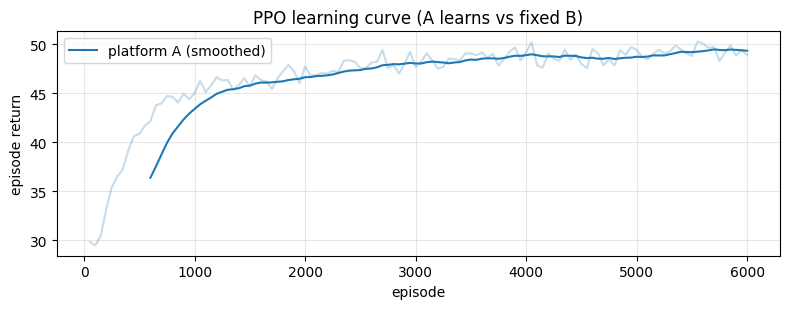

{'tag': 'A', 'verdict': 'PASS', 'failed': [], 'tail_return': 49.2775228854186, 'spread': np.float64(0.040295695624615026), 'rel_change': np.float64(0.007257311631881574), 'entropy': 1.7449546250366856}
PPO training-stability gate: PASS


In [ ]:
# ===== Stage 3: single-agent PPO baseline (Platform A vs fixed competitor) =====
ppo = train(CFG, mode="ppo", episodes=FDM_PPO_EPISODES, seed=FDM_SEED + 1, device=DEVICE)
plot_curves(ppo["curves"], ppo["learners"], "PPO learning curve (A learns vs fixed B)")
g = stability_gate(ppo["logs"], "A")
PPO_GATE = g
print(g)
PPO_GATE_OK = g["verdict"] in ("PASS", "SKIP")
print("PPO training-stability gate:", "PASS" if PPO_GATE_OK else "FAIL -> tune LR/entropy and rerun")

## 4. Evaluation: performance, risk (CVaR), and behavior (collusion proxies)

Greedy (argmax) policies, fresh environment seeds per episode. For every configuration we report the problem statement's headline metrics per platform, plus the **empirical CVaR₀.₉₅ of the episode tail loss** across evaluation episodes (the risk profile), and collusion proxies for the learned self-play market.

MAPPO (learned A,B)    | profit/h A=    365 B=    249 | fulfill A=0.869 | delay A=48.4 | tail-CVaR A=4.12 | gini A=0.24
PPO A vs neutral B     | profit/h A=    407 B=    140 | fulfill A=0.865 | delay A=48.5 | tail-CVaR A=5.06 | gini A=0.25
Rule A vs neutral B    | profit/h A=    379 B=    156 | fulfill A=0.877 | delay A=47.8 | tail-CVaR A=4.00 | gini A=0.26
Neutral vs neutral     | profit/h A=    271 B=    180 | fulfill A=0.802 | delay A=49.4 | tail-CVaR A=5.63 | gini A=0.24
Random A vs neutral B  | profit/h A=    256 B=    176 | fulfill A=0.780 | delay A=49.6 | tail-CVaR A=6.99 | gini A=0.24

               config  A_profit_per_hour  B_profit_per_hour  A_fulfillment_rate   A_S  A_mean_delay_min  A_courier_gini  A_cvar_tail  A_mean_price  A_mean_incentive
  MAPPO (learned A,B)            365.475            249.462               0.869 0.151            48.381           0.237        4.115         1.011             1.714
   PPO A vs neutral B            407.209            140.034          

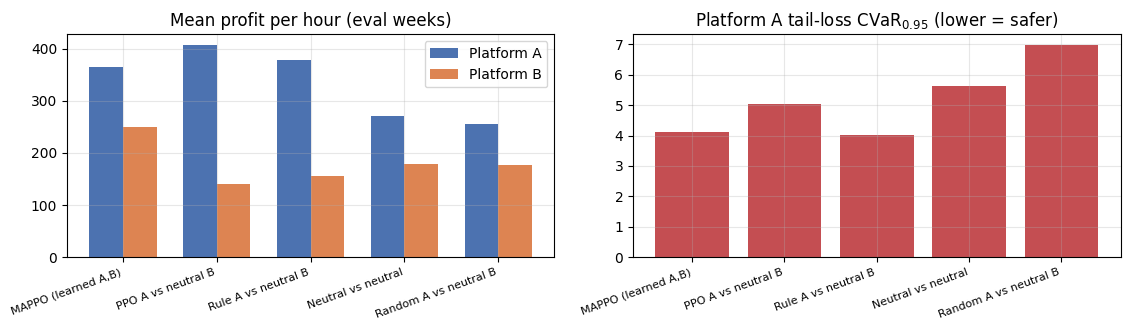

In [ ]:
# ===== Evaluation harness + headline table =====
def greedy_actor(actor):
    def act(obs, hint=None):
        with torch.no_grad():
            logits = actor.net(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE))
            return int(logits.argmax().item())
    return act

class TorchPolicy:
    def __init__(self, act_fn):
        self._act = act_fn
    def act(self, obs, hint=None):
        return self._act(obs, hint)

def evaluate(name, pol_a, pol_b, n_episodes=FDM_EVAL_EPS, seed0=50000):
    rowsA, rowsB, tailA, tailB = [], [], [], []
    for ep in range(n_episodes):
        env_e = FoodDeliveryEnv(MarketConfig(**{**CFG.__dict__, "seed": seed0 + ep}))
        tot, info = run_episode(env_e, pol_a, pol_b, seed=seed0 + ep)
        s = episode_summary(env_e.sim, CFG, spend_benchmark=SPEND_BENCHMARK)
        rowsA.append({"episode": ep, "return": tot["A"], **s["A"]})
        rowsB.append({"episode": ep, "return": tot["B"], **s["B"]})
        tailA.append(s["A"]["tail_loss"]); tailB.append(s["B"]["tail_loss"])
    dfa, dfb = pd.DataFrame(rowsA), pd.DataFrame(rowsB)
    agg = {"config": name, "n_episodes": n_episodes}
    for k in dfa.columns[1:]:
        agg["A_" + k] = float(dfa[k].mean())
        agg["B_" + k] = float(dfb[k].mean())
    agg["A_cvar_tail"] = cvar(tailA, CFG.cvar_beta)
    agg["B_cvar_tail"] = cvar(tailB, CFG.cvar_beta)
    return agg, dfa, dfb

mappo_a = TorchPolicy(greedy_actor(mappo["actors"]["A"]))
mappo_b = TorchPolicy(greedy_actor(mappo["actors"]["B"]))
ppo_a = TorchPolicy(greedy_actor(ppo["actors"]["A"]))

configs = [
    ("MAPPO (learned A,B)", mappo_a, mappo_b),
    ("PPO A vs neutral B", ppo_a, FixedPolicy(1.0, 1.0)),
    ("Rule A vs neutral B", RuleBasedPolicy(), FixedPolicy(1.0, 1.0)),
    ("Neutral vs neutral", FixedPolicy(1.0, 1.0), FixedPolicy(1.0, 1.0)),
    ("Random A vs neutral B", RandomPolicy(7), FixedPolicy(1.0, 1.0)),
]
results, per_ep = [], {}
for name, pa, pb in configs:
    agg, dfa, dfb = evaluate(name, pa, pb)
    results.append(agg); per_ep[name] = (dfa, dfb)
    print("%-22s | profit/h A=%7.0f B=%7.0f | fulfill A=%.3f | delay A=%.1f | tail-CVaR A=%.2f | gini A=%.2f"
          % (name, agg["A_profit_per_hour"], agg["B_profit_per_hour"], agg["A_fulfillment_rate"],
             agg["A_mean_delay_min"], agg["A_cvar_tail"], agg["A_courier_gini"]))

res = pd.DataFrame(results)
key_cols = ["config", "A_profit_per_hour", "B_profit_per_hour", "A_fulfillment_rate",
            "A_S", "A_mean_delay_min", "A_courier_gini", "A_cvar_tail", "A_mean_price", "A_mean_incentive"]
print()
print(res[key_cols].round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.4))
x = np.arange(len(results))
ax[0].bar(x - 0.18, res["A_profit_per_hour"], width=.36, label="Platform A", color="#4C72B0")
ax[0].bar(x + 0.18, res["B_profit_per_hour"], width=.36, label="Platform B", color="#DD8452")
ax[0].set_xticks(x); ax[0].set_xticklabels([c["config"] for c in results], rotation=20, ha="right", fontsize=8)
ax[0].set_title("Mean profit per hour (eval weeks)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(x, res["A_cvar_tail"], color="#C44E52")
ax[1].set_xticks(x); ax[1].set_xticklabels([c["config"] for c in results], rotation=20, ha="right", fontsize=8)
ax[1].set_title("Platform A tail-loss CVaR$_{0.95}$ (lower = safer)")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

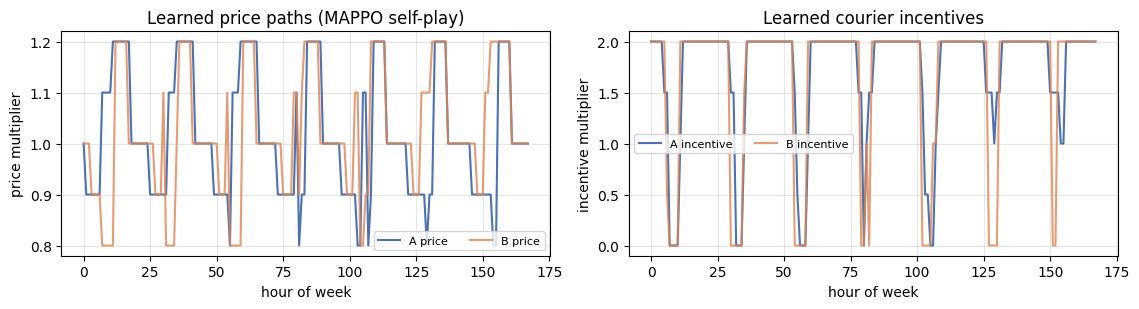

collusion proxies (MAPPO self-play week):
  price correlation        rho = 0.43
  parallel increase freq   PI  = 0.02
  profit deviation from static Nash benchmark: A=-150/hour  B=-172/hour
NOTE (problem statement): co-movement alone is NOT evidence of collusion -
common shocks and coarse grids inflate rho; Stage 14 adds statistical tests + LLM interpretability.


In [ ]:
# ===== Behavior analysis: collusion-like proxies for the learned market =====
env_c = FoodDeliveryEnv(MarketConfig(**{**CFG.__dict__, "seed": 990001}))
tot, info = run_episode(env_c, mappo_a, mappo_b, seed=990001)
prox = collusion_proxies(env_c.sim.records, nash={"A": nash["A"], "B": nash["B"]})
recs = env_c.sim.records
hours = [r.t for r in recs]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.2))
ax[0].plot(hours, [r.p_a for r in recs], label="A price", color="#4C72B0")
ax[0].plot(hours, [r.p_b for r in recs], label="B price", color="#DD8452", alpha=.8)
ax[0].set_xlabel("hour of week"); ax[0].set_ylabel("price multiplier")
ax[0].set_title("Learned price paths (MAPPO self-play)"); ax[0].legend(ncol=2, fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(hours, [r.w_a for r in recs], label="A incentive", color="#4C72B0")
ax[1].plot(hours, [r.w_b for r in recs], label="B incentive", color="#DD8452", alpha=.8)
ax[1].set_xlabel("hour of week"); ax[1].set_ylabel("incentive multiplier")
ax[1].set_title("Learned courier incentives"); ax[1].legend(ncol=2, fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("collusion proxies (MAPPO self-play week):")
print("  price correlation        rho = %.2f" % prox["price_correlation"])
print("  parallel increase freq   PI  = %.2f" % prox["parallel_increase_freq"])
print("  profit deviation from static Nash benchmark: A=%+.0f/hour  B=%+.0f/hour"
      % (prox["benchmark_deviation_A"], prox["benchmark_deviation_B"]))
print("NOTE (problem statement): co-movement alone is NOT evidence of collusion -")
print("common shocks and coarse grids inflate rho; Stage 14 adds statistical tests + LLM interpretability.")

In [ ]:
# ===== Save artifacts =====
out_dir = "gt_model_outputs"
os.makedirs(out_dir, exist_ok=True)
for tag, bundle in (("mappo", mappo), ("ppo", ppo)):
    for a in bundle["learners"]:
        torch.save({"actor": bundle["actors"][a].state_dict(),
                    "critic": bundle["critics"][a].state_dict()},
                   os.path.join(out_dir, "%s_%s.pt" % (tag, a.lower())))
res.to_csv(os.path.join(out_dir, "evaluation_results.csv"), index=False)
with open(os.path.join(out_dir, "training_logs.json"), "w") as f:
    json.dump({"mappo_logs": mappo["logs"], "ppo_logs": ppo["logs"],
               "mappo_gate": [{k: v for k, v in gr.items() if k != "failed"} for gr in gate_results],
               "ppo_gate": {k: v for k, v in PPO_GATE.items() if k != "failed"}}, f, indent=1)
calib_table.to_csv(os.path.join(out_dir, "calibration.csv"), index=False)
print("saved: %s/{mappo|ppo}_<agent>.pt, evaluation_results.csv, calibration.csv, training_logs.json" % out_dir)

saved: gt_model_outputs/{mappo|ppo}_<agent>.pt, evaluation_results.csv, calibration.csv, training_logs.json


## 5. What this notebook demonstrates — and the road ahead

**Demonstrated (Stages 1–4 of the plan, all in this one file):**
- A **calibrated** two-platform food-delivery market — calibrated from two real free datasets, with every parameter's provenance in the calibration table.
- **PPO** (single agent vs fixed competitor) and **MAPPO** (two competing platforms, centralized critics) learning pricing + courier-incentive strategies from self-play.
- Evaluation on the problem statement's terms: profit, fulfillment, delays, courier-earnings Gini, **empirical CVaR₀.₉₅ of tail loss**, collusion proxies with the required caveats, and the **training-stability gate**.

**How this maps to the remaining project stages (see WORKFLOW.md):**

| Next stage | What gets added on top of this notebook |
|---|---|
| 5–6 | Demand forecasting (LSTM → temporal transformer) + graph-temporal residual world model |
| 7 | Counterfactual rollouts — the simulator's noise stream is already CRN-ready (`snapshot_noise`) |
| 8–9 | Quantile (distributional) critic → CVaR penalty + primal-dual constraints |
| 10–12 | Adaptive risk, LLM+RAG policy prior, uncertainty gating |
| 13–15 | XAI, full collusion protocol, baselines/ablations/robustness matrix (≥3 seeds) |

**Claims boundary (problem statement, Table 2):** we can claim better risk-adjusted behavior *within the calibrated simulator*; we cannot claim real-world profitability, causal validity from proprietary data, guaranteed collusion prevention, or that LLM explanations would prove collusion.

**Reproducibility:** every run is seeded; training logs and the calibration table are saved to `gt_model_outputs/`. For the full experimental protocol, raise `FDM_EPISODES`, add seeds (the problem statement requires ≥ 3), and log runs — see the repo's `WORKFLOW.md`.